# 01 · Exploratory Data Analysis (EDA)
**Project:** Early Disease Prediction Using Machine Learning on Health Data

In this notebook we look at the data before building any model. We want to answer five simple questions:
1. Is the data clean (no missing values, no duplicates, no impossible values)?
2. Are the two classes (disease / no disease) balanced?
3. How are the clinical features spread?
4. Which features are related to the disease label?
5. Do the **original 500 rows** and the **4,500 synthetic rows** behave the same way?

> **Disclaimer:** this is a student research project on partly synthetic data. It must **not** be used for clinical diagnosis or medical decisions without supervision by qualified medical professionals.

In [1]:
import sys, warnings
from pathlib import Path

# Find the project folder whether the notebook is opened from /notebooks or from the project root
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as C, data_utils as D, evaluate as E, viz

%matplotlib inline
viz.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
from scipy import stats
from sklearn.metrics import roc_auc_score
import seaborn as sns

## 1 · Load the data and check its quality
The file `dataset_5000.csv` has 5,000 patients. Rows `P0001`–`P0500` are the original data. Rows `P0501`–`P5000` were generated (see `src/generate_synthetic_rows.py`).

In [2]:
raw = D.load_data()
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (5000, 8)


,patient_id,age,bmi,blood_pressure,glucose,cholesterol,smoking,label
0,P0001,30,20.7,136,156,191,1,1
1,P0002,67,27.7,128,87,158,0,1
2,P0003,73,18.7,106,131,273,0,0
3,P0004,43,21.7,120,172,161,0,0
4,P0005,50,37.5,95,140,206,0,0


In [3]:
report = D.validate_data(raw)
for key, value in report.items():
    print(f"{key:16s}: {value}")

n_rows          : 5000
columns_ok      : True
missing_values  : 0
duplicate_ids   : 0
duplicate_rows  : 0
out_of_range    : {'age': 0, 'bmi': 0, 'blood_pressure': 0, 'glucose': 0, 'cholesterol': 0, 'smoking': 0}
label_values_ok : True
issues          : []
passed          : True


The checks above look for wrong columns, missing values, duplicate patients and values outside the allowed clinical range. Next we run the cleaning step. It should remove nothing if the file is already clean.

In [4]:
df = D.clean_data(raw)
df["source"] = D.source_of(df)
print(f"Rows before cleaning: {len(raw)} | after cleaning: {len(df)} | removed: {len(raw) - len(df)}")
df.groupby("source")[C.TARGET].agg(rows="size", disease_share="mean")

Rows before cleaning: 5000 | after cleaning: 5000 | removed: 0


,rows,disease_share
source,,
original,500,0.394
synthetic,4500,0.512


In [5]:
df[C.FEATURES + [C.TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,5000.0,49.894,14.705,25.0,37.0,50.0,63.0,75.0
bmi,5000.0,28.702,6.250,18.0,23.3,28.7,34.0,39.8
blood_pressure,5000.0,100.256,23.385,60.0,80.0,101.0,120.0,140.0
glucose,5000.0,134.492,37.922,70.0,101.0,135.0,167.0,200.0
cholesterol,5000.0,214.778,37.809,150.0,181.0,214.0,248.0,280.0
smoking,5000.0,0.514,0.500,0.0,0.0,1.0,1.0,1.0
label,5000.0,0.500,0.500,0.0,0.0,0.5,1.0,1.0


## 2 · Class balance
A model can look good just by always guessing the bigger class. So we check how many patients have the disease.

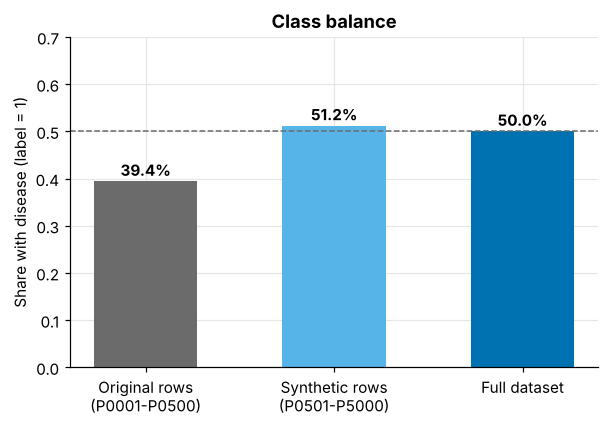

In [6]:
shares = pd.Series({
    "Original rows\n(P0001-P0500)": df.loc[df.source == "original", C.TARGET].mean(),
    "Synthetic rows\n(P0501-P5000)": df.loc[df.source == "synthetic", C.TARGET].mean(),
    "Full dataset": df[C.TARGET].mean(),
})
fig, ax = plt.subplots(figsize=(6.2, 3.9))
bars = ax.bar(shares.index, shares.values, color=[viz.GREY, viz.SKY, viz.BLUE], width=0.55)
ax.axhline(0.5, color=viz.GREY, ls="--", lw=1)
for b, v in zip(bars, shares.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.1%}", ha="center", fontweight="bold")
ax.set(ylim=(0, 0.7), ylabel="Share with disease (label = 1)", title="Class balance")
viz.save_fig(fig, "eda_class_balance")
plt.show()

The original rows have **39.4% disease** (a mild imbalance). The full 5,000-row file is exactly 50/50. Even so, the models later use class weights and the evaluation uses recall, F1 and PR-AUC, not accuracy alone.

## 3 · How are the features spread?
Histograms show where patients sit for each feature. Orange is disease, blue is no disease.

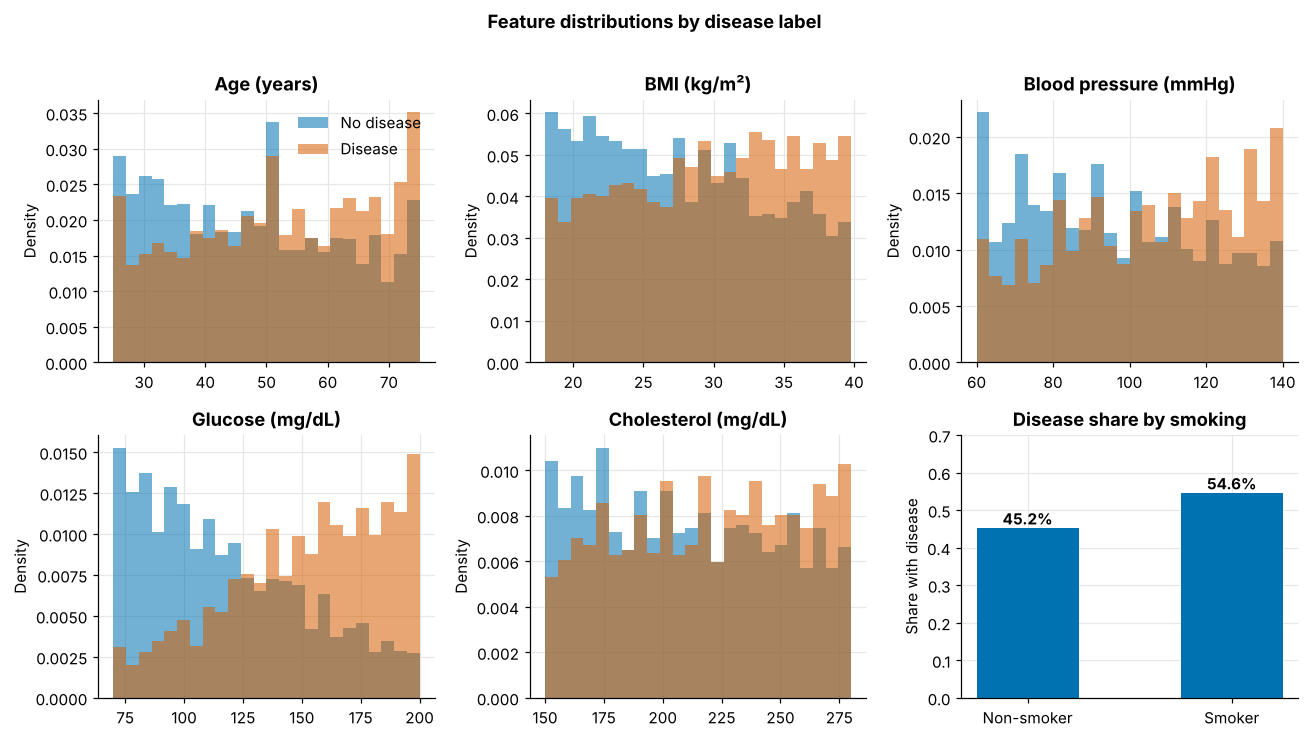

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6))
for ax, col in zip(axes.ravel(), C.NUMERIC_FEATURES):
    for lab in (0, 1):
        ax.hist(df.loc[df[C.TARGET] == lab, col], bins=24, alpha=0.55, density=True,
                color=viz.CLASS_COLORS[lab], label=viz.CLASS_NAMES[lab])
    ax.set(title=C.FEATURE_LABELS[col], ylabel="Density")
axes[0, 0].legend()
ax = axes[1, 2]
rates = df.groupby("smoking")[C.TARGET].mean()
ax.bar(["Non-smoker", "Smoker"], rates.values, color=viz.BLUE, width=0.5)
for i, v in enumerate(rates.values):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
ax.set(title="Disease share by smoking", ylabel="Share with disease", ylim=(0, 0.7))
fig.suptitle("Feature distributions by disease label", fontweight="bold", y=1.01)
fig.tight_layout()
viz.save_fig(fig, "eda_distributions")
plt.show()

Every feature is spread fairly evenly across its range, with no strong outliers. That is typical of generated data (real clinical data is usually bell-shaped with a long tail). The boxplots give the same story in a different way.

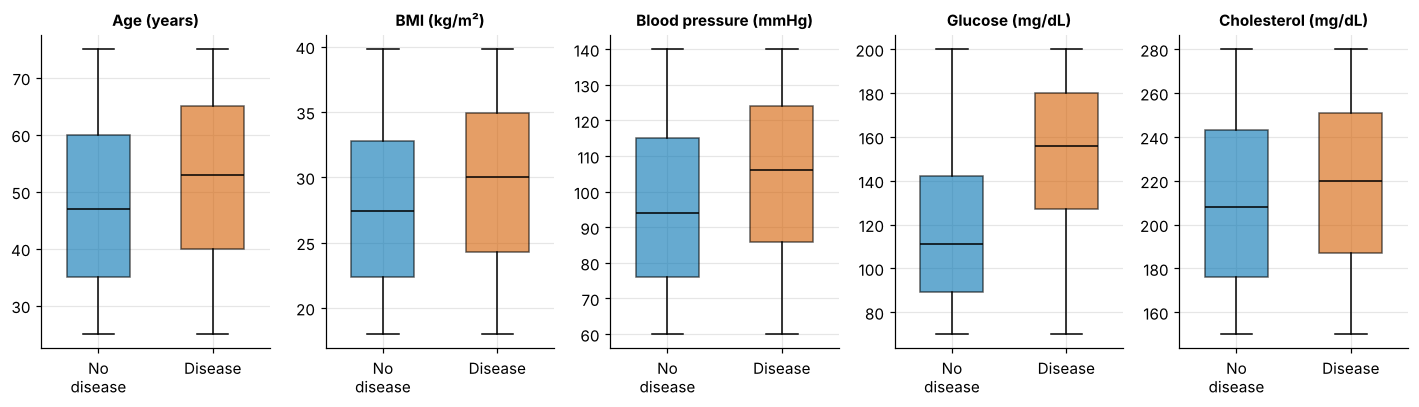

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(13, 3.8))
for ax, col in zip(axes, C.NUMERIC_FEATURES):
    data = [df.loc[df[C.TARGET] == lab, col] for lab in (0, 1)]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color="black"))
    for patch, lab in zip(bp["boxes"], (0, 1)):
        patch.set(facecolor=viz.CLASS_COLORS[lab], alpha=0.6)
    ax.set_xticks([1, 2], ["No\ndisease", "Disease"])
    ax.set_title(C.FEATURE_LABELS[col], fontsize=10)
fig.tight_layout()
viz.save_fig(fig, "eda_boxplots")
plt.show()

## 4 · Which features move with the label?
First a correlation heatmap for the whole dataset, then a closer look at each feature's power to separate the two classes.

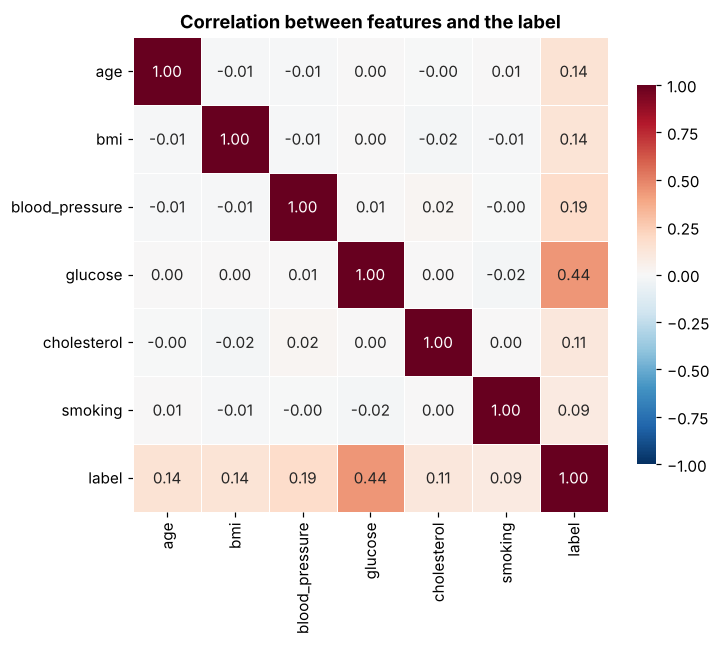

Correlation with label (full data):
glucose           0.444
blood_pressure    0.186
age               0.142
bmi               0.139
cholesterol       0.114
smoking           0.094


In [9]:
corr = df[C.FEATURES + [C.TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax, linewidths=0.5)
ax.set_title("Correlation between features and the label")
ax.grid(False)
viz.save_fig(fig, "eda_correlation")
plt.show()
print("Correlation with label (full data):")
print(corr[C.TARGET].drop(C.TARGET).sort_values(ascending=False).round(3).to_string())

Glucose is clearly the strongest single feature on the full data. Blood pressure, age, BMI, cholesterol and smoking follow with smaller effects.

The next step is important. We repeat the analysis **separately for the original rows and the synthetic rows**. For each feature we compute a single-feature AUC (0.5 means the feature cannot separate the classes at all) and a significance test (Mann-Whitney U for numbers, chi-square for smoking).

In [10]:
rows = []
for col in C.FEATURES:
    row = {"feature": C.FEATURE_LABELS[col]}
    for s in ("original", "synthetic"):
        d = df[df.source == s]
        row[f"AUC {s}"] = roc_auc_score(d[C.TARGET], d[col])
        if col == "smoking":
            p = stats.chi2_contingency(pd.crosstab(d[col], d[C.TARGET]))[1]
        else:
            p = stats.mannwhitneyu(d.loc[d[C.TARGET] == 1, col], d.loc[d[C.TARGET] == 0, col]).pvalue
        row[f"p-value {s}"] = p
    rows.append(row)
signal = pd.DataFrame(rows).set_index("feature")
shown = signal.copy()
for c in [c for c in shown if c.startswith("p-value")]:
    shown[c] = shown[c].map(lambda p: "< 0.0001" if p < 1e-4 else f"{p:.3f}")
shown.round(3)

,AUC original,p-value original,AUC synthetic,p-value synthetic
feature,,,,
Age (years),0.512,0.664,0.589,< 0.0001
BMI (kg/m²),0.490,0.708,0.590,< 0.0001
Blood pressure (mmHg),0.523,0.375,0.618,< 0.0001
Glucose (mg/dL),0.520,0.453,0.782,< 0.0001
Cholesterol (mg/dL),0.515,0.560,0.572,< 0.0001
Smoker (1 = yes),0.505,0.912,0.551,< 0.0001


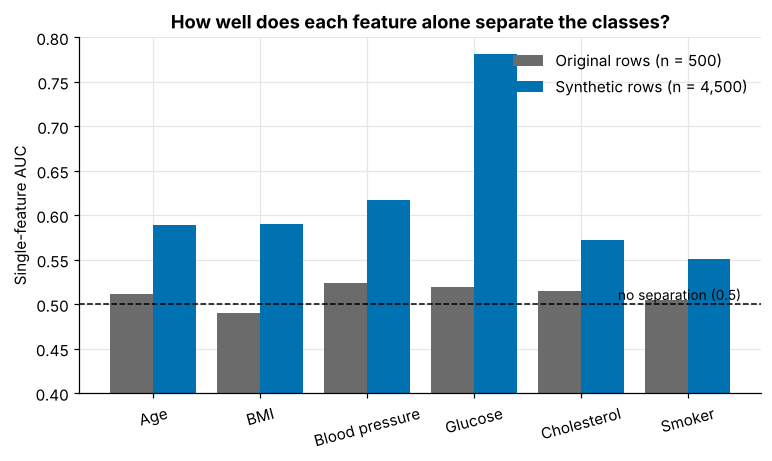

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(signal))
ax.bar(x - 0.2, signal["AUC original"], 0.4, color=viz.GREY, label="Original rows (n = 500)")
ax.bar(x + 0.2, signal["AUC synthetic"], 0.4, color=viz.BLUE, label="Synthetic rows (n = 4,500)")
ax.axhline(0.5, color="black", lw=1, ls="--")
ax.text(len(signal) - 0.5, 0.505, "no separation (0.5)", ha="right", fontsize=9)
ax.set_xticks(x, [c.split(" (")[0] for c in signal.index], rotation=15)
ax.set(ylim=(0.4, 0.8), ylabel="Single-feature AUC", title="How well does each feature alone separate the classes?")
ax.legend(loc="upper right")
viz.save_fig(fig, "eda_signal_by_source")
plt.show()

## 5 · Disease rate by clinical bands
Numbers are easier to read when grouped into familiar bands (for example glucose below 100, 100–125, 126 and above). The bars compare original and synthetic rows side by side.

*Blood pressure is split into quartiles because the file does not say whether it is systolic or diastolic, so standard clinical cut-offs would be a guess.*

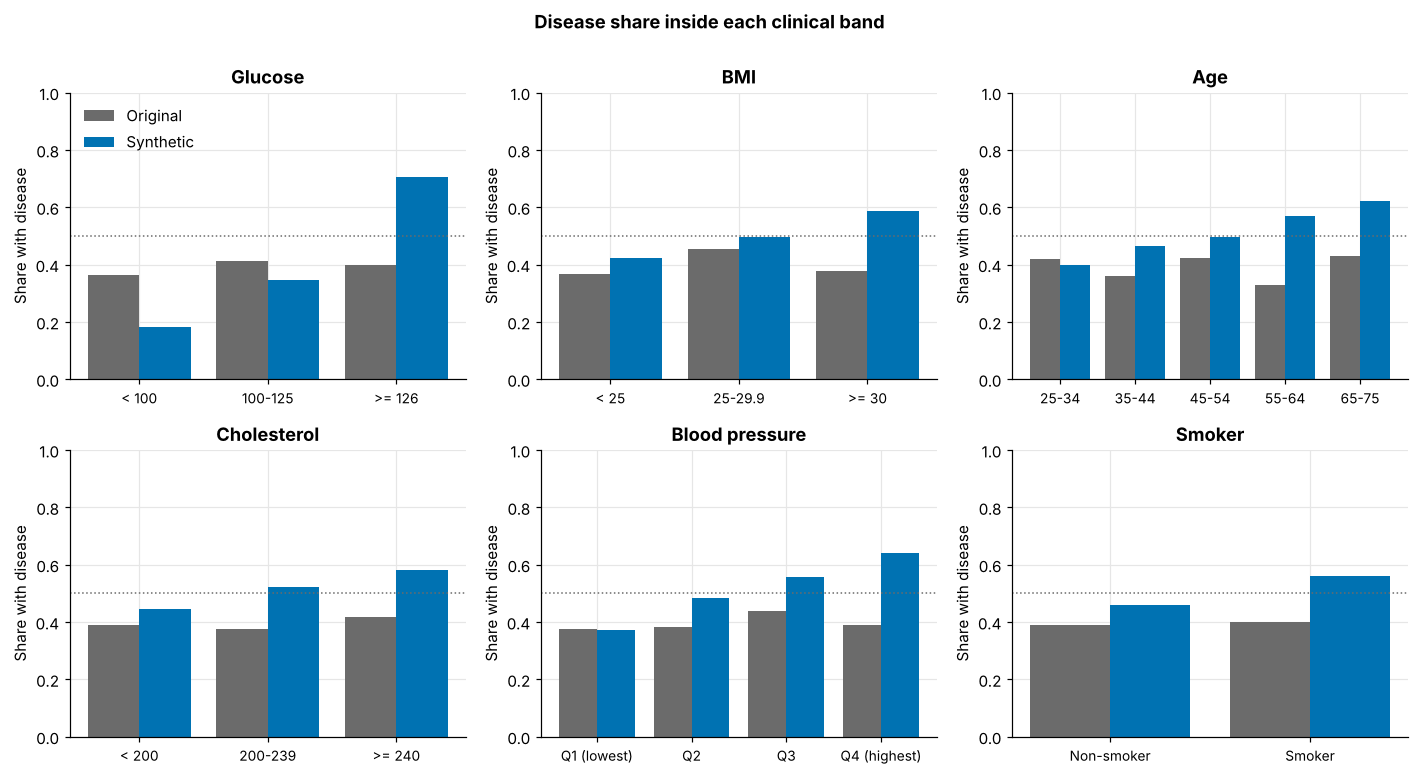

In [12]:
bands = {
    "glucose":     pd.cut(df.glucose, [0, 99, 125, 1000], labels=["< 100", "100-125", ">= 126"]),
    "bmi":         pd.cut(df.bmi, [0, 24.9, 29.9, 100], labels=["< 25", "25-29.9", ">= 30"]),
    "age":         pd.cut(df.age, [0, 34, 44, 54, 64, 100], labels=["25-34", "35-44", "45-54", "55-64", "65-75"]),
    "cholesterol": pd.cut(df.cholesterol, [0, 199, 239, 1000], labels=["< 200", "200-239", ">= 240"]),
    "blood_pressure": pd.qcut(df.blood_pressure, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]),
    "smoking":     df.smoking.map({0: "Non-smoker", 1: "Smoker"}),
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (col, band) in zip(axes.ravel(), bands.items()):
    rate = df.groupby([band, "source"], observed=True)[C.TARGET].mean().unstack()
    rate = rate[["original", "synthetic"]]
    idx = np.arange(len(rate))
    ax.bar(idx - 0.2, rate["original"], 0.4, color=viz.GREY, label="Original")
    ax.bar(idx + 0.2, rate["synthetic"], 0.4, color=viz.BLUE, label="Synthetic")
    ax.axhline(0.5, color=viz.GREY, ls=":", lw=1)
    ax.set_xticks(idx, rate.index, fontsize=9)
    ax.set(title=C.FEATURE_LABELS[col].split(" (")[0], ylim=(0, 1), ylabel="Share with disease")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Disease share inside each clinical band", fontweight="bold", y=1.0)
fig.tight_layout()
viz.save_fig(fig, "eda_rate_by_band")
plt.show()

## 6 · Key findings
1. **The data is clean.** 5,000 rows, no missing values, no duplicate patients or records, and every value sits inside its allowed range. The cleaning step removed nothing.
2. **Classes.** The 500 original rows are 39.4% disease; the full file is exactly 50% / 50%. Class weights and recall / F1 / PR-AUC are still used later, so the pipeline also works on an imbalanced file.
3. **Strongest feature: glucose.** On the full data its correlation with the label is 0.44, followed by blood pressure (0.19), age (0.14), BMI (0.14), cholesterol (0.11) and smoking (0.09). In the synthetic rows, the disease share climbs from about 18% (glucose below 100) to about 70% (glucose 126 or higher).
4. **The two parts of the file behave very differently.** In the 500 original rows no feature is significant (all p-values above 0.37, single-feature AUC between 0.49 and 0.52, which is chance). In the 4,500 synthetic rows every feature is significant (glucose AUC 0.78, the others 0.55 to 0.62).
5. **What this means.** Any model trained on the full file learns mostly from the synthetic rows, whose feature-to-disease links were built into the generator as an assumption. Results must be described as *partly synthetic* and not as proof about real patients. Notebook 02 measures this gap directly.